In [2]:
import pandas as pd 
df=pd.read_csv("weather.csv")
df.head()

,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy


In [3]:
df.shape

(170928, 10)

In [4]:
df.columns


Index(['country', 'location_name', 'latitude', 'longitude', 'timezone',
       'last_updated_epoch', 'last_updated', 'temperature_celsius',
       'temperature_fahrenheit', 'condition_text'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170928 entries, 0 to 170927
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   country                 170928 non-null  object 
 1   location_name           170928 non-null  object 
 2   latitude                170928 non-null  float64
 3   longitude               170928 non-null  float64
 4   timezone                170928 non-null  object 
 5   last_updated_epoch      170928 non-null  int64  
 6   last_updated            170928 non-null  object 
 7   temperature_celsius     170928 non-null  float64
 8   temperature_fahrenheit  170928 non-null  float64
 9   condition_text          170928 non-null  object 
dtypes: float64(4), int64(1), object(5)
memory usage: 13.0+ MB


In [6]:
df.describe()

,latitude,longitude,last_updated_epoch,temperature_celsius,temperature_fahrenheit
count,170928.000000,170928.000000,1.709280e+05,170928.000000,170928.000000
mean,19.283424,21.805043,1.753891e+09,21.445260,70.602908
std,24.373383,65.766968,2.196145e+07,9.271741,16.689010
min,-41.300000,-175.200000,1.715849e+09,-29.800000,-21.600000
25%,4.050300,-6.836100,1.734949e+09,16.200000,61.100000
50%,17.250000,21.433300,1.753863e+09,23.600000,74.400000
75%,40.400000,49.882200,1.772865e+09,27.700000,81.800000
max,65.300000,179.220000,1.791870e+09,79.300000,174.700000


In [7]:
df.isnull().sum()

country                   0
location_name             0
latitude                  0
longitude                 0
timezone                  0
last_updated_epoch        0
last_updated              0
temperature_celsius       0
temperature_fahrenheit    0
condition_text            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.drop_duplicates(inplace=True)

print("Remaining Duplicates:", df.duplicated().sum())

Remaining Duplicates: 0


In [10]:
df.shape

(170927, 10)

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,170927.0,1.928343e+01,2.437345e+01,-4.130000e+01,4.050300e+00,1.725000e+01,4.040000e+01,6.530000e+01
longitude,170927.0,2.180458e+01,6.576688e+01,-1.752000e+02,-6.836100e+00,2.143330e+01,4.988220e+01,1.792200e+02
last_updated_epoch,170927.0,1.753891e+09,2.196147e+07,1.715849e+09,1.734949e+09,1.753863e+09,1.772865e+09,1.791870e+09
temperature_celsius,170927.0,2.144520e+01,9.271732e+00,-2.980000e+01,1.620000e+01,2.360000e+01,2.770000e+01,7.930000e+01
temperature_fahrenheit,170927.0,7.060279e+01,1.668899e+01,-2.160000e+01,6.110000e+01,7.440000e+01,8.180000e+01,1.747000e+02


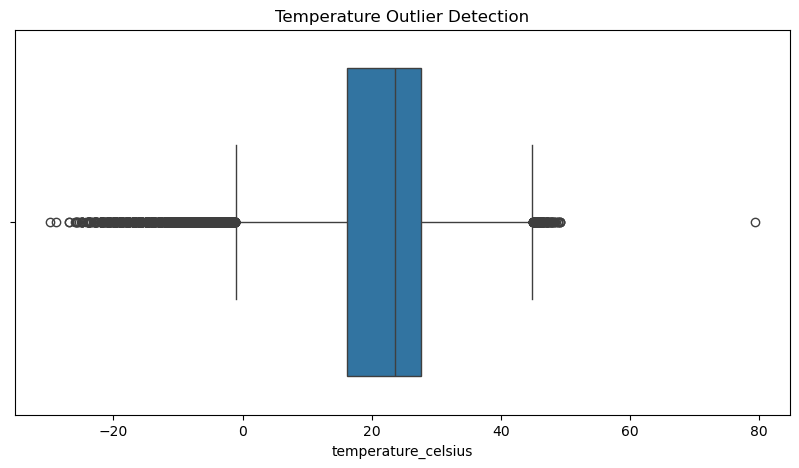

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.boxplot(x=df['temperature_celsius'])
plt.title("Temperature Outlier Detection")
plt.show()

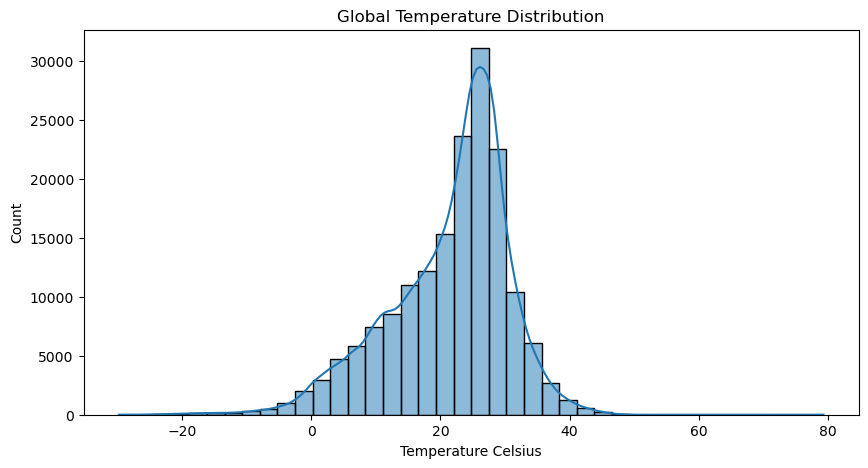

In [13]:
plt.figure(figsize=(10,5))
sns.histplot(df['temperature_celsius'], bins=40, kde=True)
plt.title("Global Temperature Distribution")
plt.xlabel("Temperature Celsius")
plt.show()

In [14]:
df['last_updated'] = pd.to_datetime(df['last_updated'])

print("Total Unique Dates:", df['last_updated'].nunique())
print("Starting Date:", df['last_updated'].min())
print("Ending Date:", df['last_updated'].max())

Total Unique Dates: 28420
Starting Date: 2024-05-16 01:45:00
Ending Date: 2026-10-13 18:45:00


In [15]:
df.groupby('location_name')['last_updated'].count().describe()

count    268.000000
mean     637.787313
std      366.611526
min        1.000000
25%      302.250000
50%      875.500000
75%      877.000000
max      880.000000
Name: last_updated, dtype: float64

In [20]:
print("Unique Dates:", df['last_updated'].nunique())

print("Start Date:", df['last_updated'].min())

print("End Date:", df['last_updated'].max())

Unique Dates: 28420
Start Date: 2024-05-16 01:45:00
End Date: 2026-10-13 18:45:00


In [21]:
df['condition_text'].value_counts().head(10)

condition_text
Sunny                 50181
Partly cloudy         42875
Patchy rain nearby    16166
Partly Cloudy         11628
Overcast              10169
Clear                  9626
Mist                   6775
Light rain shower      4824
Light rain             4814
Cloudy                 2596
Name: count, dtype: int64

In [22]:
country_temp = df.groupby('country')['temperature_celsius'].mean()

country_temp = country_temp.sort_values(ascending=False)

country_temp.head(10)

country
Saudi Arabien           45.000000
Marrocos                40.300000
Turkménistan            37.800000
Турция                  34.000000
Qatar                   32.974201
United Arab Emirates    32.532005
Cambodia                32.093273
Oman                    31.804328
Kuwait                  31.639795
Djibouti                31.493714
Name: temperature_celsius, dtype: float64

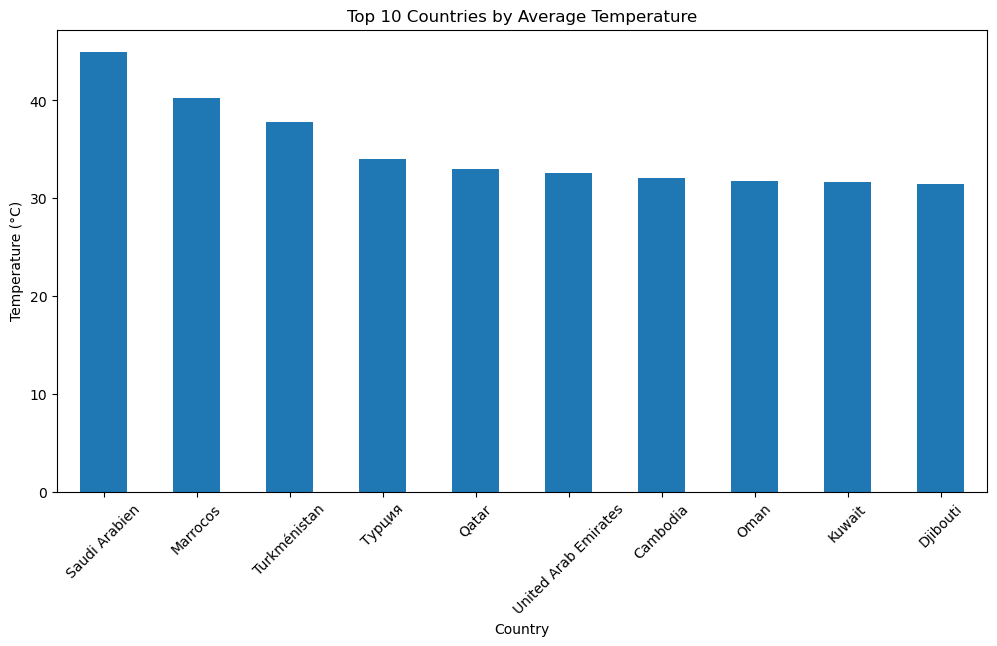

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

country_temp.head(10).plot(kind='bar')

plt.title("Top 10 Countries by Average Temperature")
plt.xlabel("Country")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)

plt.show()

In [24]:
print("Unique Locations:", df['location_name'].nunique())

print("Records per Location:")
print(df.groupby('location_name').size().describe())

Unique Locations: 268
Records per Location:
count    268.000000
mean     637.787313
std      366.611526
min        1.000000
25%      302.250000
50%      875.500000
75%      877.000000
max      880.000000
dtype: float64


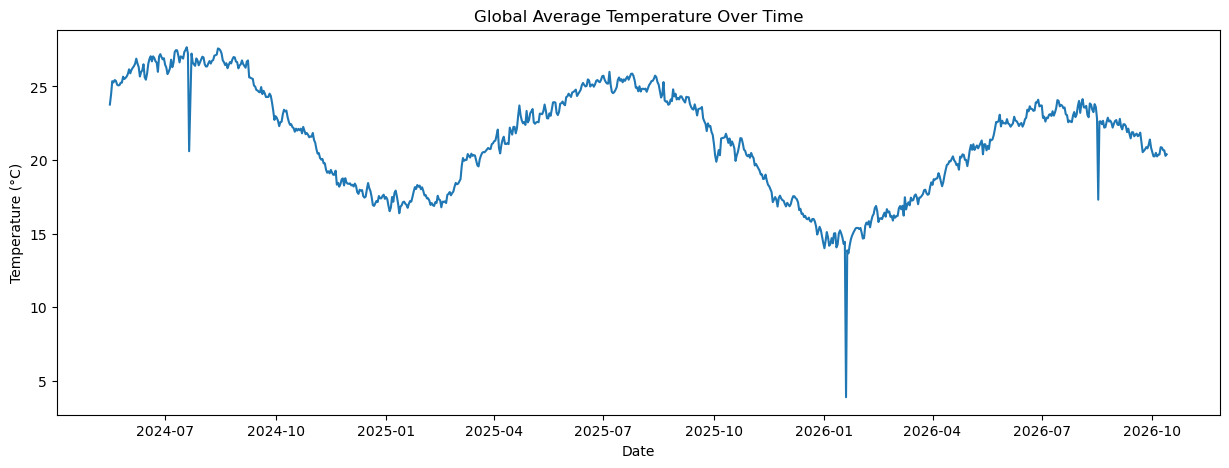

In [25]:
daily_temp = df.groupby(
    df['last_updated'].dt.date
)['temperature_celsius'].mean()

plt.figure(figsize=(15,5))
daily_temp.plot()

plt.title("Global Average Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.show()

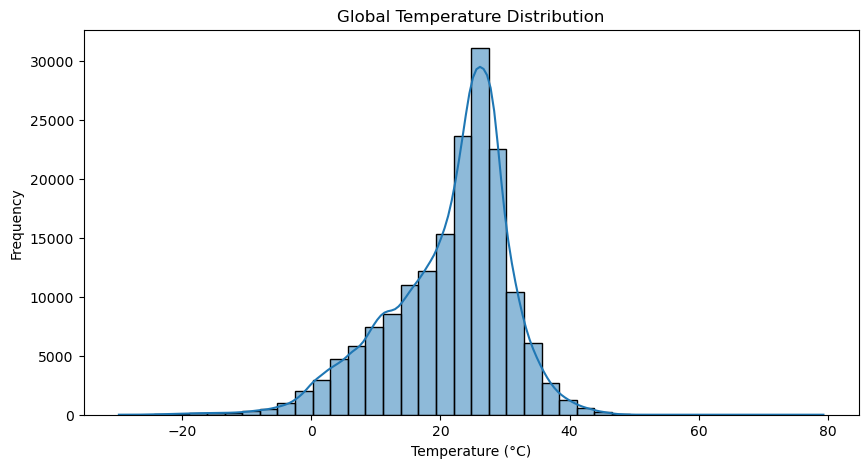

In [26]:
plt.figure(figsize=(10,5))

sns.histplot(df['temperature_celsius'], bins=40, kde=True)

plt.title("Global Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

plt.show()

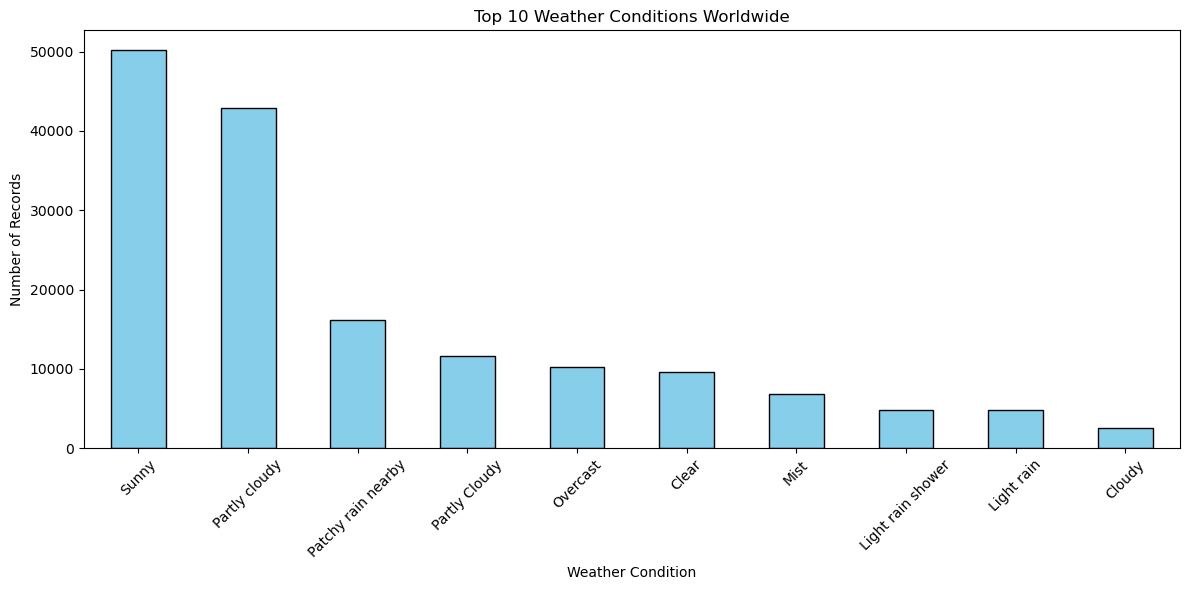

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

df['condition_text'].value_counts().head(10).plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Top 10 Weather Conditions Worldwide')
plt.xlabel('Weather Condition')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
country,170927,211,Bulgaria,2027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location_name,170927,268,Sanaa,880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,170927.0,NaN,NaN,NaN,19.283426,-41.3,4.0503,17.25,40.4,65.3,24.373455
longitude,170927.0,NaN,NaN,NaN,21.80458,-175.2,-6.8361,21.4333,49.8822,179.22,65.766883
timezone,170927,201,Asia/Bangkok,3043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last_updated_epoch,170927.0,NaN,NaN,NaN,1753890918.953705,1715849100.0,1734948900.0,1753863300.0,1772865000.0,1791870300.0,21961467.917626
last_updated,170927,NaN,NaN,NaN,2025-07-30 18:05:17.877807616,2024-05-16 01:45:00,2024-12-23 06:15:00,2025-07-30 11:15:00,2026-03-07 12:00:00,2026-10-13 18:45:00,NaN
temperature_celsius,170927.0,NaN,NaN,NaN,21.445197,-29.8,16.2,23.6,27.7,79.3,9.271732
temperature_fahrenheit,170927.0,NaN,NaN,NaN,70.602795,-21.6,61.1,74.4,81.8,174.7,16.688993
condition_text,170927,58,Sunny,50181,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
country_temp = (
    df.groupby('country')['temperature_celsius']
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 Hottest Countries:")
display(country_temp.head(10))

print("Top 10 Coldest Countries:")
display(country_temp.tail(10))

Top 10 Hottest Countries:


country
Saudi Arabien           45.000000
Marrocos                40.300000
Turkménistan            37.800000
Турция                  34.000000
Qatar                   32.974201
United Arab Emirates    32.532005
Cambodia                32.093273
Oman                    31.804328
Kuwait                  31.639795
Djibouti                31.493714
Name: temperature_celsius, dtype: float64

Top 10 Coldest Countries:


country
Lithuania                   10.086317
Estonia                      9.800114
Russia                       9.603326
Finland                      9.483371
United States of America     9.431465
Andorra                      9.017995
Norway                       8.356970
Canada                       6.623516
Mongolia                     6.059521
Iceland                      5.722489
Name: temperature_celsius, dtype: float64

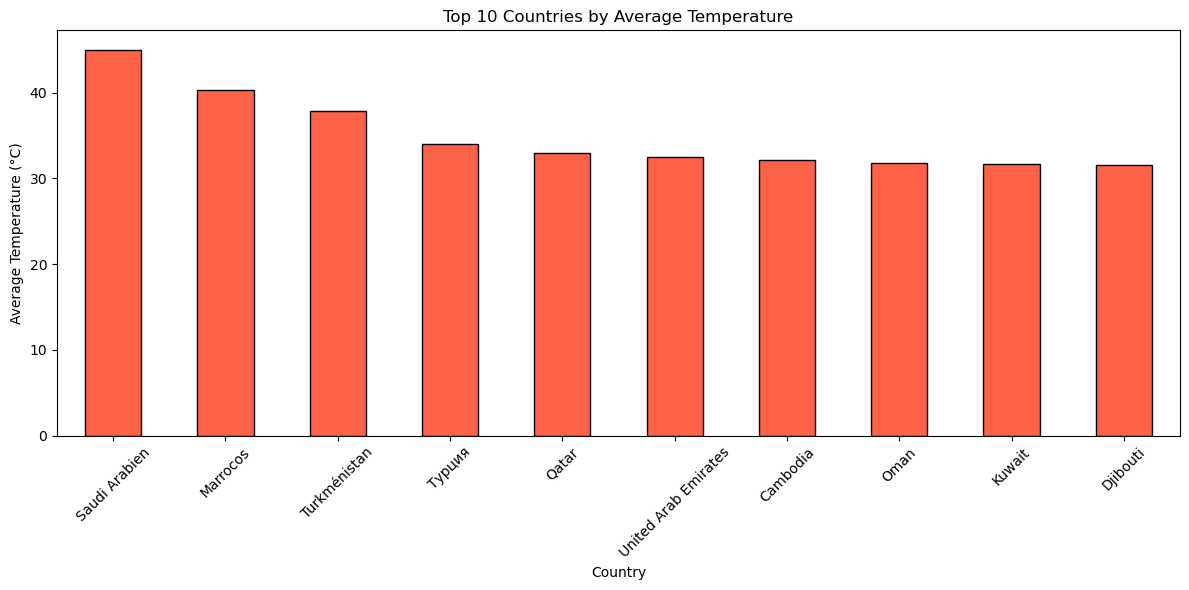

In [30]:
plt.figure(figsize=(12,6))

country_temp.head(10).plot(
    kind='bar',
    color='tomato',
    edgecolor='black'
)

plt.title('Top 10 Countries by Average Temperature')
plt.xlabel('Country')
plt.ylabel('Average Temperature (°C)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# Remove duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Check dataset
print("Dataset Shape:", df.shape)

print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicate Records:")
print(df.duplicated().sum())

df.head()

Dataset Shape: (170927, 10)
Missing Values:
0
Duplicate Records:
0


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,2024-05-16 13:15:00,26.6,79.8,Partly Cloudy
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,2024-05-16 10:45:00,19.0,66.2,Partly cloudy
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,2024-05-16 09:45:00,23.0,73.4,Sunny
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,2024-05-16 10:45:00,6.3,43.3,Light drizzle
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,2024-05-16 09:45:00,26.0,78.8,Partly cloudy


In [32]:
# Convert last_updated into datetime
df['last_updated'] = pd.to_datetime(df['last_updated'])

# Extract date and time features
df['year'] = df['last_updated'].dt.year
df['month'] = df['last_updated'].dt.month
df['day'] = df['last_updated'].dt.day
df['hour'] = df['last_updated'].dt.hour
df['day_of_week'] = df['last_updated'].dt.dayofweek

# Display new features
df[['last_updated', 'year', 'month',
    'day', 'hour', 'day_of_week']].head(10)

,last_updated,year,month,day,hour,day_of_week
0,2024-05-16 13:15:00,2024,5,16,13,3
1,2024-05-16 10:45:00,2024,5,16,10,3
2,2024-05-16 09:45:00,2024,5,16,9,3
3,2024-05-16 10:45:00,2024,5,16,10,3
4,2024-05-16 09:45:00,2024,5,16,9,3
5,2024-05-16 04:45:00,2024,5,16,4,3
6,2024-05-16 05:45:00,2024,5,16,5,3
7,2024-05-16 12:45:00,2024,5,16,12,3
8,2024-05-16 18:45:00,2024,5,16,18,3
9,2024-05-16 10:45:00,2024,5,16,10,3


In [33]:
print("Updated Dataset Shape:", df.shape)
print("\nNew Columns:")
print(df.columns.tolist())

Updated Dataset Shape: (170927, 15)

New Columns:
['country', 'location_name', 'latitude', 'longitude', 'timezone', 'last_updated_epoch', 'last_updated', 'temperature_celsius', 'temperature_fahrenheit', 'condition_text', 'year', 'month', 'day', 'hour', 'day_of_week']


In [34]:

# Select Features and Target

features = ['latitude', 'longitude']
target = 'temperature_celsius'

X = df[features]
y = df[target]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (170927, 2)
Target Shape: (170927,)


In [35]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (136741, 2)
Testing Data: (34186, 2)


In [37]:

from sklearn.linear_model import LinearRegression

# Create Model
lr_model = LinearRegression()

# Train Model
lr_model.fit(X_train, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [38]:

y_pred = lr_model.predict(X_test)

print("Actual Values:", y_test.head(10).values)
print("Predicted Values:", y_pred[:10])


Actual Values: [21.3 28.2 28.  25.2 25.1 21.5 22.1 32.  27.2 27.9]
Predicted Values: [23.16287179 28.0920023  20.66859744 19.66758168 26.79974513 23.56325835
 27.25314657 27.5636664  21.69289738 29.34125401]


In [39]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Performance")
print("-----------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Score (%):", r2 * 100)


Linear Regression Model Performance
-----------------------------------
MAE: 6.63328329194737
MSE: 74.45377198760221
RMSE: 8.62865991841156
R2 Score: 0.14386525238077874
R2 Score (%): 14.386525238077875


In [42]:
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# XGBoost
from xgboost import XGBRegressor

# Models
models = {
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )
}

# Store Results
results = []

# Train and Evaluate
for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2,
        "R2 Score (%)": r2 * 100
    })

# Comparison Table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

print("\n========== MODEL PERFORMANCE COMPARISON ==========")
display(results_df.round(4))

# Best Model
best_model_name = results_df.iloc[0]["Model"]

print("\nBest Model:", best_model_name)
print("Best R2 Score:", round(
    results_df.iloc[0]["R2 Score (%)"], 2
), "%")



Training Decision Tree...

Training Random Forest...

Training Gradient Boosting...

Training XGBoost...

========== MODEL PERFORMANCE COMPARISON ==========


,Model,MAE,MSE,RMSE,R2 Score,R2 Score (%)
1,Random Forest,4.0986,33.9330,5.8252,0.6098,60.9809
0,Decision Tree,4.0986,33.9334,5.8252,0.6098,60.9804
3,XGBoost,4.2810,36.3993,6.0332,0.5814,58.1449
2,Gradient Boosting,4.6481,41.5232,6.4438,0.5225,52.2530



Best Model: Random Forest
Best R2 Score: 60.98 %


In [43]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Random Forest Hyperparameter Tuning

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

best_rf = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation R2:")
print(random_search.best_score_)


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}

Best Cross Validation R2:
0.6031167762146606


In [44]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predict using tuned model
y_pred_tuned = best_rf.predict(X_test)

# Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred_tuned)
mse = mean_squared_error(y_test, y_pred_tuned)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_tuned)

# Display Results
print("TUNED RANDOM FOREST - FINAL PERFORMANCE")
print("----------------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Score (%):", r2 * 100)

# Actual vs Predicted
comparison = pd.DataFrame({
    "Actual Temperature": y_test.iloc[:15].values,
    "Predicted Temperature": y_pred_tuned[:15]
})

display(comparison.round(2))


TUNED RANDOM FOREST - FINAL PERFORMANCE
----------------------------------------
MAE: 4.098339280520782
MSE: 33.92944949720141
RMSE: 5.824899097598293
R2 Score: 0.6098494420540218
R2 Score (%): 60.98494420540218


,Actual Temperature,Predicted Temperature
0,21.3,18.73
1,28.2,27.72
2,28.0,27.07
3,25.2,23.45
4,25.1,19.28
5,21.5,22.26
6,22.1,20.25
7,32.0,24.17
8,27.2,31.25
9,27.9,25.44


In [45]:

import joblib
import os

# Create Model Folder
os.makedirs("models", exist_ok=True)

# Save Tuned Random Forest Model
joblib.dump(best_rf, "models/weather_prediction_model.pkl")



['models/weather_prediction_model.pkl']

In [46]:

# Save Feature Names
joblib.dump(
    list(X_train.columns),
    "models/weather_feature_names.pkl"
)


['models/weather_feature_names.pkl']

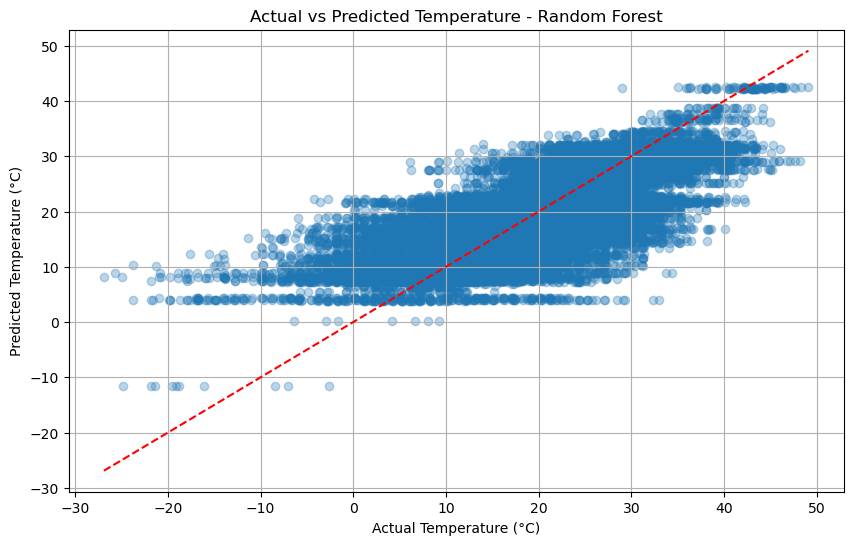

In [47]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred_tuned, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("Actual vs Predicted Temperature - Random Forest")

plt.grid(True)
plt.show()
